# 02 - Train the 30-day readmission risk model

**Question:** Can we rank discharged patients better than the LACE spreadsheet coordinators use today, so the roughly 20% of patients they can call are the right 20%?

**We compare three approaches** on the same held-out, later time period:
1. **LACE baseline**: today's process.
2. **Gradient-boosted trees on structured EHR features** from `lakeview_health.gold_discharge_features`.
3. **The same model plus GenAI social-risk features** from `lakeview_ml.note_social_risk` (ai_extract).

**Business metric:** *recall in the top 20% by risk*, meaning the share of all readmissions that land in the group coordinators can actually call. AUC is reported too.

**Guardrails:** temporal split (train on earlier discharges, test on later ones); only discharge-time features (no outreach or follow-up attendance, so no leakage); payer and language are excluded as inputs and used only for the fairness check. Every run is tracked in MLflow, and the model is registered in Unity Catalog.

In [0]:
import numpy as np, pandas as pd, mlflow
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

CAT = "simo_show_case_catalog"
EXPERIMENT = "/Users/sihua.an@databricks.com/FE_Bar/lakeview_readmission_experiment"
MODEL_NAME = f"{CAT}.lakeview_ml.readmission_risk"
SEED = 7
mlflow.set_experiment(EXPERIMENT)

df = spark.sql(f"""
  SELECT f.*, s.sdoh_lives_alone, s.sdoh_caregiver_available, s.sdoh_transportation_barrier,
         s.sdoh_medication_cost_barrier, s.sdoh_health_literacy_concern, s.sdoh_substance_use
  FROM {CAT}.lakeview_health.gold_discharge_features f
  JOIN {CAT}.lakeview_ml.note_social_risk s USING (encounter_id)
  WHERE f.label_window_complete
""").toPandas()
df["readmitted_30d"] = df["readmitted_30d"].astype(bool)
print(df.shape, "| discharge range:", df.discharge_date.min(), "to", df.discharge_date.max())
print("Readmission share:", round(df.readmitted_30d.mean(), 4))

2026/11/04 05:59:43 INFO mlflow.tracking.fluent: Experiment with name '/Users/sihua.an@databricks.com/FE_Bar/lakeview_readmission_experiment' does not exist. Creating a new experiment.
{"ts": "2026-11-04 05:59:44.395", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMzkyNzc3NzQwODkzMDM3MBABIAEyJDAxYTFhNTI0LTFjZGUtN2ZhZC1iMjE0LTEyZTkwY2QxZmVmZTokMGVhMmU4M2MtMGNkMy0zODA0LThlYTktZmYyYzhiZmJmN2ZmSgwIwZOr1wYQgNO46QJQAVgBYAFokp6FgfDEow2IAQA=.", "context": {}}
{"ts": "2026-11-04 05:59:44.395", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMzkyNzc3NzQwODkzMDM3MBABIAEyJDAxYTFhNTI0LTFjZGUtN2ZhZC1iMjE0LTEyZTkwY2QxZmVmZTokMGVhMmU4M2MtMGNkMy0zODA0LThlYTktZmYyYzhiZmJmN2ZmSgwIwZOr1wYQgNO46QJQAVgBYAFokp6FgfDEow2IAQA=.", "context": {}}
{"ts": "2026-11-04 05:59:44.395", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg":

(12735, 42) | discharge range: 2025-01-02 to 2026-10-04
Readmission share: 0.1574


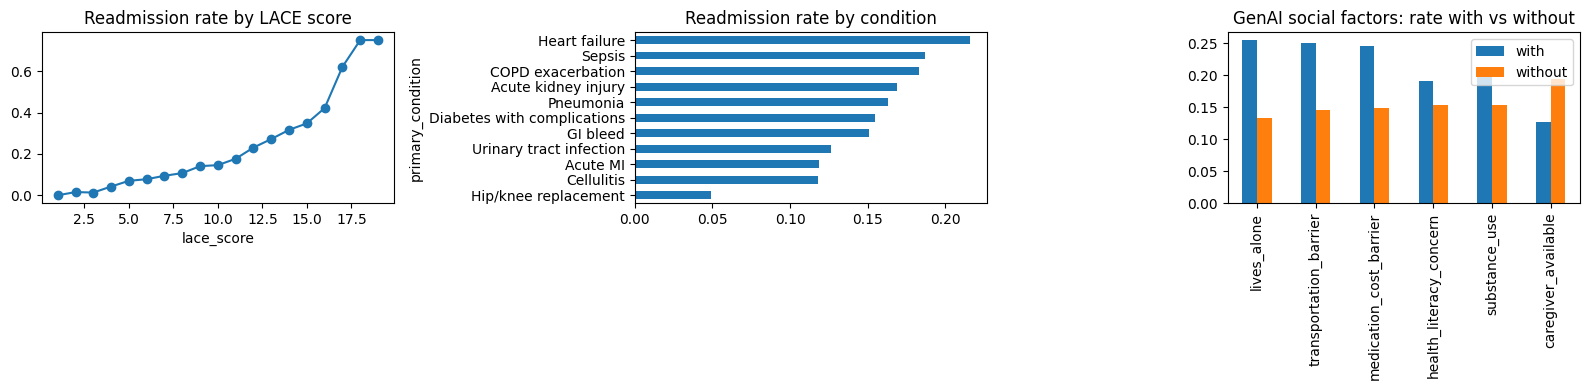

       los_days  ed_visits_prior_6m  ...  lace_score  age_at_admit
count  12735.00            12735.00  ...    12735.00      12735.00
mean       4.61                0.86  ...        9.35         63.27
std        3.02                1.02  ...        2.84         17.30
min        1.00                0.00  ...        1.00         23.00
25%        2.00                0.00  ...        7.00         52.00
50%        4.00                1.00  ...        9.00         67.00
75%        6.00                1.00  ...       11.00         76.00
max       26.00                9.00  ...       19.00         98.00

[8 rows x 7 columns]


In [0]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("lace_score").readmitted_30d.mean().plot(ax=axes[0], marker="o", title="Readmission rate by LACE score")
df.groupby("primary_condition").readmitted_30d.mean().sort_values().plot.barh(ax=axes[1], title="Readmission rate by condition")
sd = ["sdoh_lives_alone","sdoh_transportation_barrier","sdoh_medication_cost_barrier","sdoh_health_literacy_concern","sdoh_substance_use","sdoh_caregiver_available"]
pd.DataFrame({c.replace("sdoh_",""): [df[df[c]].readmitted_30d.mean(), df[~df[c]].readmitted_30d.mean()] for c in sd}, index=["with","without"]).T.plot.bar(ax=axes[2], title="GenAI social factors: rate with vs without")
plt.tight_layout(); plt.show()
print(df[["los_days","ed_visits_prior_6m","prior_admissions_12m","comorbidity_count","num_discharge_meds","lace_score","age_at_admit"]].describe().round(2))

In [0]:
NUM = ["age_at_admit","los_days","ed_visits_prior_6m","prior_admissions_12m","comorbidity_count","num_discharge_meds",
       "sodium","hemoglobin","creatinine","bnp","abnormal_lab_count"]
BOOL = ["has_dementia","has_heart_failure_dx","has_ckd","has_depression","on_insulin","on_anticoagulant","on_opioid","followup_scheduled_7d"]
CATS = ["primary_condition","admission_type","discharge_disposition","sex"]
GENAI = ["sdoh_lives_alone","sdoh_caregiver_available","sdoh_transportation_barrier","sdoh_medication_cost_barrier","sdoh_health_literacy_concern","sdoh_substance_use"]
STRUCT_FEATURES = NUM + BOOL + CATS
ALL_FEATURES = STRUCT_FEATURES + GENAI

for c in BOOL + GENAI:
    df[c] = df[c].astype(int)

# Temporal split: discharge_date is a real event time and scoring predicts future discharges -> hold out the latest period.
CUTOFF = pd.Timestamp("2026-05-01").date()
train, test = df[df.discharge_date < CUTOFF], df[df.discharge_date >= CUTOFF]
print(f"Train: {len(train):,} discharges before {CUTOFF} | Test: {len(test):,} discharges {CUTOFF} to {test.discharge_date.max()}")
print("Minority class (readmitted) share - train:", round(train.readmitted_30d.mean(), 3), "test:", round(test.readmitted_30d.mean(), 3))
print(pd.DataFrame({"feature": ALL_FEATURES, "type": ["numeric"]*len(NUM) + ["binary"]*len(BOOL) + ["categorical/nominal"]*len(CATS) + ["binary (GenAI ai_extract)"]*len(GENAI)}).to_string(index=False))

Train: 9,642 discharges before 2026-05-01 | Test: 3,093 discharges 2026-05-01 to 2026-10-04
Minority class (readmitted) share - train: 0.156 test: 0.162
                     feature                      type
                age_at_admit                   numeric
                    los_days                   numeric
          ed_visits_prior_6m                   numeric
        prior_admissions_12m                   numeric
           comorbidity_count                   numeric
          num_discharge_meds                   numeric
                      sodium                   numeric
                  hemoglobin                   numeric
                  creatinine                   numeric
                         bnp                   numeric
          abnormal_lab_count                   numeric
                has_dementia                    binary
        has_heart_failure_dx                    binary
                     has_ckd                    binary
              has_depr

In [0]:
def make_pipeline(features):
    num = [f for f in features if f in NUM + BOOL + GENAI]
    cat = [f for f in features if f in CATS]
    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
    ])
    # Readmissions are ~16% of rows (minority class) -> class_weight='balanced' re-weights the rare class.
    clf = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=40,
                                         l2_regularization=1.0, class_weight="balanced", early_stopping=True,
                                         validation_fraction=0.15, random_state=SEED)
    return Pipeline([("pre", pre), ("clf", clf)])

def recall_at_top(y, score, frac=0.20):
    k = int(np.ceil(frac * len(y)))
    idx = np.argsort(-np.asarray(score), kind="stable")[:k]
    return np.asarray(y)[idx].sum() / np.asarray(y).sum(), np.asarray(y)[idx].mean()

def evaluate(name, y, score, prob=None):
    rec, prec = recall_at_top(y, score)
    m = {"auc": roc_auc_score(y, score), "pr_auc": average_precision_score(y, score), "recall_top20pct": rec, "precision_top20pct": prec}
    if prob is not None:
        m["brier"] = brier_score_loss(y, prob)
    return {"approach": name, **{k: round(v, 4) for k, v in m.items()}}

results, models = [], {}
y_tr, y_te = train.readmitted_30d.values, test.readmitted_30d.values
# random tie-break so LACE's coarse integer score isn't helped or hurt by row order
lace_rank = test.lace_score.values + np.random.default_rng(SEED).uniform(0, 0.01, len(test))
results.append(evaluate("1. LACE baseline (today)", y_te, lace_rank))

for name, feats in [("2. GBT - structured EHR", STRUCT_FEATURES), ("3. GBT - structured + GenAI social risk", ALL_FEATURES)]:
    with mlflow.start_run(run_name=name) as run:
        pipe = make_pipeline(feats).fit(train[feats], y_tr)
        p = pipe.predict_proba(test[feats])[:, 1]
        r = evaluate(name, y_te, p, p)
        mlflow.log_params({"features": len(feats), "genai_features": name.startswith("3"), "split": f"temporal cutoff {CUTOFF}",
                           "n_train": len(train), "n_test": len(test), "seed": SEED, "best_iter": pipe["clf"].n_iter_})
        mlflow.log_metrics({k: v for k, v in r.items() if k != "approach"})
        mlflow.set_tags({"project": "lakeview_readmissions", "fe_bar": "true"})
        results.append(r); models[name] = (pipe, feats, p, run.info.run_id)

comparison = pd.DataFrame(results)
display(comparison)

approach,auc,pr_auc,recall_top20pct,precision_top20pct,brier
1. LACE baseline (today),0.6859,0.3207,0.4072,0.3296,null
2. GBT - structured EHR,0.6995,0.3405,0.4052,0.3279,0.2201
3. GBT - structured + GenAI social risk,0.7315,0.3704,0.4271,0.3457,0.2099


In [0]:
base, best = comparison.iloc[0], comparison.iloc[2]
n_test_readmits = int(y_te.sum())
months = (pd.Timestamp(test.discharge_date.max()) - pd.Timestamp(CUTOFF)).days / 30.4
extra_caught = (best.recall_top20pct - base.recall_top20pct) * n_test_readmits
print(f"Test period: {len(test):,} discharges, {n_test_readmits} readmissions over {months:.1f} months")
print(f"Calling the top 20% by LACE reaches {base.recall_top20pct:.1%} of future readmissions;")
print(f"calling the top 20% by the GenAI-enhanced model reaches {best.recall_top20pct:.1%}  (+{(best.recall_top20pct-base.recall_top20pct)*100:.1f} pts, relative +{best.recall_top20pct/base.recall_top20pct-1:.0%})")
print(f"=> about {extra_caught:.0f} more at-risk patients reached with the SAME coordinator capacity in this sample period")
print(f"GenAI lift over structured-only: AUC {comparison.iloc[1].auc} -> {best.auc}; recall@20% {comparison.iloc[1].recall_top20pct:.1%} -> {best.recall_top20pct:.1%}")

Test period: 3,093 discharges, 501 readmissions over 5.1 months
Calling the top 20% by LACE reaches 40.7% of future readmissions;
calling the top 20% by the GenAI-enhanced model reaches 42.7%  (+2.0 pts, relative +5%)
=> about 10 more at-risk patients reached with the SAME coordinator capacity in this sample period
GenAI lift over structured-only: AUC 0.6995 -> 0.7315; recall@20% 40.5% -> 42.7%


In [0]:
pipe, feats, p_best, _ = models["3. GBT - structured + GenAI social risk"]
t = test.assign(score=p_best)
thr = np.quantile(p_best, 0.80)   # top-20% flag threshold
rows = []
for col in ["payer", "primary_language"]:
    for g, d in t.groupby(col):
        if d.readmitted_30d.sum() >= 10 and d.readmitted_30d.nunique() == 2:
            rows.append({"group": f"{col}={g}", "n": len(d), "readmit_rate": round(d.readmitted_30d.mean(), 3),
                         "auc": round(roc_auc_score(d.readmitted_30d, d.score), 3),
                         "flagged_share": round((d.score >= thr).mean(), 3),
                         "recall_in_flagged": round(d[d.score >= thr].readmitted_30d.sum() / d.readmitted_30d.sum(), 3)})
fair = pd.DataFrame(rows)
display(fair)
print("Groups with readmission recall in the flagged set >10 pts below overall:",
      fair[fair.recall_in_flagged < best.recall_top20pct - 0.10].group.tolist() or "none")

group,n,readmit_rate,auc,flagged_share,recall_in_flagged
payer=Commercial,790,0.124,0.736,0.113,0.286
payer=Medicaid,395,0.132,0.712,0.106,0.25
payer=Medicare,1196,0.192,0.738,0.258,0.513
payer=Medicare Advantage,598,0.172,0.695,0.279,0.476
payer=Self-pay,114,0.158,0.764,0.114,0.333
primary_language=English,2632,0.161,0.721,0.195,0.404
primary_language=Spanish,313,0.153,0.763,0.211,0.5
primary_language=Vietnamese,101,0.218,0.839,0.287,0.636


Groups with readmission recall in the flagged set >10 pts below overall: ['payer=Commercial', 'payer=Medicaid']


In [0]:
from mlflow.models import infer_signature
from mlflow import MlflowClient

final = make_pipeline(ALL_FEATURES).fit(df[ALL_FEATURES], df.readmitted_30d.values)
X_sig = df[ALL_FEATURES].head(100)
signature = infer_signature(X_sig, final.predict_proba(X_sig)[:, 1])
with mlflow.start_run(run_name="final - structured + GenAI (refit on all labeled data)") as run:
    mlflow.log_params({"n_final_fit": len(df), "n_train": len(train), "n_test": len(test), "features": ALL_FEATURES, "seed": SEED})
    mlflow.log_metrics({f"holdout_{k}": v for k, v in best.items() if k != "approach"})
    mlflow.log_table(comparison, "model_comparison.json")
    mlflow.log_table(fair, "fairness_by_group.json")
    model_info = mlflow.sklearn.log_model(final, name="model", signature=signature, input_example=df[ALL_FEATURES].head(3),
                                          pyfunc_predict_fn="predict_proba")
print("Logged:", model_info.model_uri)

# Isolated serving-readiness check: installs pip requirements from scratch in a fresh env
loaded = mlflow.pyfunc.load_model(model_info.model_uri)
assert loaded.metadata.signature is not None and loaded.input_example is not None
mlflow.models.predict(model_uri=model_info.model_uri, input_data=loaded.input_example, env_manager="uv")

mlflow.set_registry_uri("databricks-uc")
mv = mlflow.register_model(model_uri=model_info.model_uri, name=MODEL_NAME, await_registration_for=300)
MlflowClient(registry_uri="databricks-uc").set_registered_model_alias(MODEL_NAME, "champion", mv.version)
print(f"Registered {MODEL_NAME} version {mv.version} with alias @champion")

/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
🔗 View Logged Model at: https://fevm-simo-show-case.cloud.databricks.com/ml/experiments/3927777408930371/models/m-9ae7b59f9c3244109b6f05559d8214c0?o=7474647551528722


Logged: models:/m-9ae7b59f9c3244109b6f05559d8214c0


2026/11/04 06:01:06 INFO mlflow.models.flavor_backend_registry: Selected backend for flavor 'python_function'


2026/11/04 06:01:07 INFO mlflow.utils.virtualenv: Creating a new environment in /tmp/virtualenv_envs/mlflow-4bfa1453a32f1d960f57094995d698fada99ed43 with python version 3.12.3 using uv
Using CPython 3.12.3 interpreter at: /usr/bin/python3.12
Creating virtual environment at: /tmp/virtualenv_envs/mlflow-4bfa1453a32f1d960f57094995d698fada99ed43
Activate with: source /tmp/virtualenv_envs/mlflow-4bfa1453a32f1d960f57094995d698fada99ed43/bin/activate
2026/11/04 06:01:08 INFO mlflow.utils.virtualenv: Installing dependencies
Using Python 3.12.3 environment at: /tmp/virtualenv_envs/mlflow-4bfa1453a32f1d960f57094995d698fada99ed43
Resolved 3 packages in 107ms
 Downloaded setuptools
 Downloaded pip
Prepared 3 packages in 127ms
Installed 3 packages in 127ms
 + pip==25.3
 + setuptools==80.9.0
 + wheel==0.45.1
Using Python 3.12.3 environment at: /tmp/virtualenv_envs/mlflow-4bfa1453a32f1d960f57094995d698fada99ed43
Resolved 89 packages in 735ms
 Downloaded mlflow-tracing
 Downloaded kiwisolver
 Download

{"predictions": [[0.5215504658970214, 0.47844953410297864], [0.6640346625082132, 0.33596533749178686], [0.4547532886655903, 0.5452467113344097]]}

Successfully registered model 'simo_show_case_catalog.lakeview_ml.readmission_risk'.


Uploading artifacts:   0%|          | 0/12 [00:00<?, ?it/s]

🔗 Created version '1' of model 'simo_show_case_catalog.lakeview_ml.readmission_risk': https://fevm-simo-show-case.cloud.databricks.com/explore/data/models/simo_show_case_catalog/lakeview_ml/readmission_risk/version/1?o=7474647551528722


Registered simo_show_case_catalog.lakeview_ml.readmission_risk version 1 with alias @champion


### Results on the held-out period (May to Oct 2026: 3,093 discharges, 501 readmissions)

| Approach | AUC | PR-AUC | Recall in top 20% | Precision in top 20% |
| --- | --- | --- | --- | --- |
| LACE (today) | 0.686 | 0.321 | 40.7% | 33.0% |
| GBT, structured EHR only | 0.700 | 0.341 | 40.5% | 32.8% |
| **GBT + GenAI social risk** | **0.732** | **0.370** | **42.7%** | **34.6%** |

**What this shows (stated honestly):**
* Structured EHR data alone barely beats LACE. **Most of the improvement comes from the GenAI-extracted social factors** (AUC +0.03 over structured only, +0.046 over LACE).
* The improvement at the top of the list is real but modest (+2.0 percentage points of readmissions reached with the same staff, or 5% more in relative terms). The bigger operational gains come from the workflow: a daily list, the reasons behind each score, and measured outreach.
* Probabilities come from a class-weighted model and are **not calibrated** (Brier 0.21). The app therefore shows risk **tiers and percentiles**, not raw probabilities. Calibrating them (isotonic) is a next step.
* **Fairness:** Commercial and Medicaid patients are flagged less often (11% vs 26% for Medicare), mostly because they are younger with lower base rates (12-13% vs 19%). Recall within the flagged group is lower for them, so this is listed as a monitoring item, not hidden.

The model is registered as `simo_show_case_catalog.lakeview_ml.readmission_risk` v1 with alias `@champion`. It passed the isolated serving-readiness check (`env_manager=uv`).